# Etapa 3 — Engenharia de Atributos (Silver → Gold)

**Objetivo:** transformar a camada silver em uma **camada gold** pronta para análise
bivariada, testes inferenciais e modelagem preditiva de `valor_contratado`.

**O que fazemos aqui:**
1. Criar **features temporais, de prazo, geográficas, setoriais e de cliente**.
2. Reduzir **cardinalidade** de variáveis categóricas (top-N + "OUTROS").
3. Aplicar **encoding numérico** (one-hot e frequência) para deixar a base pronta para modelagem.
4. Validar qualidade final (nulos, tipos, cardinalidade).

In [ ]:
# =============================================================
# 1. SETUP, PALETA E CARREGAMENTO
# =============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta institucional (mesma do notebook de EDA)
paleta_cores = {
    "azul":    "#003B5C",
    "laranja": "#F15A22",
    "cinza":   "#D9D9D9",
    "verde":   "#00A99D",
}
PALETA = list(paleta_cores.values())

sns.set_theme(style="whitegrid", context="notebook",
              palette=PALETA, font_scale=1.2)
plt.rcParams["figure.figsize"]   = (10, 4)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.spines.top"]  = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["grid.color"]       = paleta_cores["cinza"]

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42
TARGET = "valor_contratado"

# Caminhos
PATH_SILVER = "../data/silver/operacoes_bndes_silver.parquet"
PATH_GOLD   = "../data/gold/bnds_features.parquet"

# Carrega silver
df = pd.read_parquet(PATH_SILVER)
df["data_contratacao"] = pd.to_datetime(df["data_contratacao"], errors="coerce")

# Reaplica filtro do universo (mesmo da etapa 1)
df_feat = df[df[TARGET].notna() & (df[TARGET] > 0)].copy()
df_feat = df_feat.drop_duplicates(subset="id_contrato", keep="first")

print(f"Base de trabalho (silver filtrada): {df_feat.shape[0]:,} linhas × {df_feat.shape[1]} colunas")

Base de trabalho (silver filtrada): 8,294 linhas × 44 colunas


## Princípios que guiam esta etapa

| Princípio | Regra adotada |
|---|---|
| **Leakage** | Nenhuma feature pode usar `valor_desembolsado`, `situacao_operacao` ou qualquer estatística que dependa do futuro da contratação. |
| **PII / cardinalidade** | `cnpj_cliente`, `nome_cliente` e `id_contrato` saem da base de features. `cnpj_cliente` só é usado indiretamente para agregados históricos **time-aware**. |
| **Cardinalidade** | Categóricas com mais de 15 níveis → top 10 + "OUTROS". CNAE granular (classe/subclasse/descrição) sai; mantemos setor e subsetor BNDES. |
| **Encoding** | Categóricas com ≤ 15 níveis → **one-hot**. Acima disso → **frequência** (proporção na base). Ordinais já numéricos são mantidos. |
| **Reprodutibilidade** | Toda transformação é determinística; `random_state` fixo; ordem temporal preservada. |

## 1. Exclusões obrigatórias

Removemos colunas que **não podem** entrar como features:

- **Leakage:** `valor_desembolsado` (consequência posterior), `situacao_operacao` (estado posterior).
- **Identificadores:** `id_contrato`, `id_municipio` (usar `sigla_uf` + região).
- **PII:** `nome_cliente`, `cnpj_cliente` (alta cardinalidade + privacidade).
- **Texto bruto:** `descricao_projeto` (mantemos `qtd_palavras_descricao`, já na silver).
- **Redundância CNAE:** `classe_cnae`, `subclasse_cnae`, `descricao_cnae` (granularidade excessiva; ficamos com `setor_bndes` e `subsetor_bndes`).

In [6]:
# =============================================================
# 2. EXCLUSÕES (leakage, PII, IDs e redundância)
# =============================================================
COLUNAS_REMOVER = [
    # Leakage
    "valor_desembolsado",
    "situacao_operacao",
    # Identificadores / PII
    "id_contrato",
    "id_municipio",
    "cnpj_cliente",
    "nome_cliente",
    "cnpj_instituicao_financeira_credenciada",
    # Texto bruto
    "descricao_projeto",
    # CNAE granular (redundante)
    "classe_cnae",
    "subclasse_cnae",
    "descricao_cnae",
    # Já representado por sigla_uf
    "id_municipio",
]

df_feat = df_feat.drop(columns=[c for c in COLUNAS_REMOVER if c in df_feat.columns])

print(f"Após exclusões: {df_feat.shape[0]:,} linhas × {df_feat.shape[1]} colunas")
print("Colunas restantes:")
print(df_feat.columns.tolist())

Após exclusões: 8,294 linhas × 38 colunas
Colunas restantes:
['razao_social_cliente', 'sigla_uf', 'nome_municipio', 'data_contratacao', 'valor_contratado', 'tipo_fonte_recursos', 'custo_financeiro', 'taxa_juros', 'prazo_carencia', 'prazo_amortizacao', 'modalidade_apoio', 'forma_apoio', 'produto', 'tipo_instrumento_financeiro', 'indicador_inovacao', 'area_operacional_bndes', 'setor_cnae_bndes', 'subsetor_agrupado_cnae_bndes', 'descricao_subclasse', 'setor_bndes', 'subsetor_bndes', 'porte_cliente', 'natureza_cliente', 'nome_instituicao_financeira_credenciada', 'tipo_garantia', 'situacao_contrato', 'data_apuracao', 'tem_excepcionalidade', 'ano_contratacao', 'mes_contratacao', 'prazo_total_meses', 'grupo_taxa_juros', 'grupo_taxa_juros_ordinal', 'flag_apoio_direto', 'flag_reembolsavel', 'flag_cliente_publico', 'qtd_palavras_descricao', 'porte_cliente_ordinal']


## 2. Features temporais

A data de contratação gera features de **sazonalidade** e de **posição temporal**,
úteis para capturar padrões cíclicos e tendência.

- `ano_contratacao`, `mes_contratacao` já existem na silver.
- Acrescentamos `trimestre` e `mes_sin`/`mes_cos` (codificação cíclica do mês,
  para o modelo não interpretar dezembro como "12× janeiro").

In [7]:
# =============================================================
# 3. FEATURES TEMPORAIS
# =============================================================
df_feat["trimestre"] = df_feat["data_contratacao"].dt.quarter

# Codificação cíclica do mês (evita descontinuidade dez→jan)
df_feat["mes_sin"] = np.sin(2 * np.pi * df_feat["mes_contratacao"] / 12)
df_feat["mes_cos"] = np.cos(2 * np.pi * df_feat["mes_contratacao"] / 12)

print("Features temporais criadas: trimestre, mes_sin, mes_cos")
df_feat[["data_contratacao", "ano_contratacao", "mes_contratacao",
         "trimestre", "mes_sin", "mes_cos"]].head()

Features temporais criadas: trimestre, mes_sin, mes_cos


,data_contratacao,ano_contratacao,mes_contratacao,trimestre,mes_sin,mes_cos
0,2009-06-30,2009,6,2,0.00,-1.00
1,2009-06-29,2009,6,2,0.00,-1.00
2,2009-06-30,2009,6,2,0.00,-1.00
3,2009-06-30,2009,6,2,0.00,-1.00
4,2009-10-09,2009,10,4,-0.87,0.50


## 3. Features de prazo

`prazo_total_meses` já existe na silver. Acrescentamos:

- `razao_carencia` = `prazo_carencia / prazo_total_meses` (peso da carência no contrato).
- `prazo_total_anos` = `prazo_total_meses / 12` (leitura de negócio).
- `flag_longo_prazo` = 1 se `prazo_total_meses ≥ 60`.

Tratamos divisão por zero com `np.where` (prazo_total nunca é 0 na prática, mas é defensivo).

In [8]:
# =============================================================
# 4. FEATURES DE PRAZO
# =============================================================
# Cálculo seguro de razão (evita divisão por zero)
prazo_total_seguro = df_feat["prazo_total_meses"].replace(0, np.nan)

df_feat["razao_carencia"]  = (df_feat["prazo_carencia"] / prazo_total_seguro).fillna(0)
df_feat["prazo_total_anos"] = df_feat["prazo_total_meses"] / 12
df_feat["flag_longo_prazo"] = (df_feat["prazo_total_meses"] >= 60).astype(int)

print("Features de prazo criadas: razao_carencia, prazo_total_anos, flag_longo_prazo")
df_feat[["prazo_carencia", "prazo_amortizacao", "prazo_total_meses",
         "razao_carencia", "prazo_total_anos", "flag_longo_prazo"]].head()

Features de prazo criadas: razao_carencia, prazo_total_anos, flag_longo_prazo


,prazo_carencia,prazo_amortizacao,prazo_total_meses,razao_carencia,prazo_total_anos,flag_longo_prazo
0,18,90,108,0.17,9.00,1
1,24,84,108,0.22,9.00,1
2,6,102,108,0.06,9.00,1
3,30,90,120,0.25,10.00,1
4,30,90,120,0.25,10.00,1


## 4. Features geográficas

`sigla_uf` tem 27 níveis — tratável, mas a **região** ajuda a reduzir ruído e a
dar interpretação macro. Criamos:

- `regiao` (Norte, Nordeste, Centro-Oeste, Sudeste, Sul) a partir de `sigla_uf`.
- `flag_sudeste_sul` (concentração histórica de crédito).

In [9]:
# =============================================================
# 5. FEATURES GEOGRÁFICAS
# =============================================================
UF_REGIAO = {
    "AC":"Norte","AP":"Norte","AM":"Norte","PA":"Norte",
    "RO":"Norte","RR":"Norte","TO":"Norte",
    "AL":"Nordeste","BA":"Nordeste","CE":"Nordeste","MA":"Nordeste",
    "PB":"Nordeste","PE":"Nordeste","PI":"Nordeste","RN":"Nordeste","SE":"Nordeste",
    "DF":"Centro-Oeste","GO":"Centro-Oeste","MT":"Centro-Oeste","MS":"Centro-Oeste",
    "ES":"Sudeste","MG":"Sudeste","RJ":"Sudeste","SP":"Sudeste",
    "PR":"Sul","RS":"Sul","SC":"Sul",
}

df_feat["regiao"] = df_feat["sigla_uf"].map(UF_REGIAO).fillna("Ignorado")
df_feat["flag_sudeste_sul"] = df_feat["regiao"].isin(["Sudeste", "Sul"]).astype(int)

print("Distribuição por região:")
print(df_feat["regiao"].value_counts())

Distribuição por região:
regiao
Sudeste         3547
Sul             1814
Nordeste        1206
Ignorado         809
Centro-Oeste     590
Norte            328
Name: count, dtype: int64


## 5. Features setoriais e de área operacional

`setor_bndes` e `subsetor_bndes` podem ter dezenas de níveis. Aplicamos a
**regra top-N + "OUTROS"** para manter a matriz de features enxuta:

- Categóricas com **> 15 níveis** → mantém os **10 mais frequentes** e agrupa o resto em `"OUTROS"`.
- Isso reduz ruído e evita matrizes esparsas enormes no one-hot.

In [10]:
# =============================================================
# 6. REDUÇÃO DE CARDINALIDADE — TOP-N + "OUTROS"
# =============================================================
def agrupar_top_n(serie: pd.Series, n: int = 10, rotulo: str = "OUTROS") -> pd.Series:
    """Mantém os n valores mais frequentes; os demais viram `rotulo`."""
    top = serie.value_counts().nlargest(n).index
    return serie.where(serie.isin(top), rotulo)

# Colunas candidatas a top-N
COLUNAS_TOP_N = [
    "setor_bndes", "subsetor_bndes",
    "produto", "instrumento_financeiro",
    "area_operacional", "tipo_garantia",
    "tipo_excepcionalidade", "fonte_recurso",
    "custo_financeiro",
    "nome_instituicao_financeira_credenciada",
]

for col in COLUNAS_TOP_N:
    if col in df_feat.columns:
        antes = df_feat[col].nunique()
        df_feat[col] = agrupar_top_n(df_feat[col], n=10)
        depois = df_feat[col].nunique()
        print(f"{col:45s} | níveis antes: {antes:4d} → depois: {depois:2d}")

setor_bndes                                   | níveis antes:    4 → depois:  4
subsetor_bndes                                | níveis antes:   20 → depois: 11
produto                                       | níveis antes:   17 → depois: 11
tipo_garantia                                 | níveis antes:   16 → depois: 11
custo_financeiro                              | níveis antes:   30 → depois: 11
nome_instituicao_financeira_credenciada       | níveis antes:   41 → depois: 11


## 6. Features de cliente

A silver já traz `porte_cliente_ordinal`, `flag_cliente_publico` e
`natureza_cliente`. Acrescentamos uma feature de **tamanho institucional**:

- `flag_micro_pequena` = 1 se `porte_cliente_ordinal` ∈ {1, 2} (micro ou pequena).
- `flag_grande` = 1 se `porte_cliente_ordinal` = 4 (grande).

In [11]:
# =============================================================
# 7. FEATURES DE CLIENTE
# =============================================================
df_feat["flag_micro_pequena"] = df_feat["porte_cliente_ordinal"].isin([1, 2]).astype(int)
df_feat["flag_grande"]        = (df_feat["porte_cliente_ordinal"] == 4).astype(int)

print("Distribuição de porte ordinal:")
print(df_feat["porte_cliente_ordinal"].value_counts().sort_index())

Distribuição de porte ordinal:
porte_cliente_ordinal
0     475
1     474
2     593
3     817
4    5935
Name: count, dtype: int64


## 7. Agregações históricas **time-aware** (sem leakage)

Aqui está o ponto mais delicado da engenharia. Queremos capturar o "histórico do
segmento" (UF, setor, porte) **sem usar o futuro**. Regra:

> Para cada linha, calcular a estatística **apenas com linhas anteriores**
> (mesma UF / mesmo setor / mesmo porte). Implementamos com
> `groupby(...).shift(1).expanding().agg(...)`.

Criamos três famílias de features:

- `*_hist_ticket_medio` — média histórica do valor contratado no segmento.
- `*_hist_n_contratos` — número de contratos anteriores no segmento.
- `*_hist_volume` — soma histórica do valor contratado no segmento.

Segmentos: `sigla_uf`, `setor_bndes`, `porte_cliente_ordinal`.

**Tratamento do primeiro registro de cada grupo** (sem histórico):
- contagens e somas → `0`
- médias → média global (documentado como aproximação; em produção, usar média do treino)

In [12]:
# =============================================================
# 8. AGREGAÇÕES HISTÓRICAS (TIME-AWARE)
# =============================================================
def adicionar_historicos(frame: pd.DataFrame,
                         grupo: str,
                         prefixo: str,
                         alvo: str = TARGET) -> pd.DataFrame:
    """
    Adiciona 3 features históricas por grupo:
      - ticket_medio (média do alvo apenas com registros anteriores)
      - n_contratos (contagem de registros anteriores)
      - volume     (soma do alvo apenas com registros anteriores)
    Assume que `frame` está ordenado por data.
    """
    g = frame.groupby(grupo, group_keys=False)[alvo]

    # Média histórica (shift para excluir a linha atual; expanding acumula)
    media_hist = g.apply(lambda s: s.shift(1).expanding().mean())
    frame[f"{prefixo}_hist_ticket_medio"] = media_hist.fillna(frame[alvo].mean())

    # Contagem histórica = quantas linhas anteriores no grupo
    frame[f"{prefixo}_hist_n_contratos"] = frame.groupby(grupo).cumcount()

    # Soma histórica
    soma_hist = g.apply(lambda s: s.shift(1).expanding().sum())
    frame[f"{prefixo}_hist_volume"] = soma_hist.fillna(0)

    return frame

# Ordena por data ANTES de agregar (essencial para time-aware)
df_feat = df_feat.sort_values("data_contratacao").reset_index(drop=True)

for grupo, prefixo in [
    ("sigla_uf",              "uf"),
    ("setor_bndes",           "setor"),
    ("porte_cliente_ordinal", "porte"),
]:
    df_feat = adicionar_historicos(df_feat, grupo, prefixo)
    print(f"Históricos de {grupo} → {prefixo}_hist_* criados")

# Conferência rápida
df_feat[[
    "data_contratacao", "sigla_uf",
    "uf_hist_ticket_medio", "uf_hist_n_contratos", "uf_hist_volume",
]].head(10)

Históricos de sigla_uf → uf_hist_* criados
Históricos de setor_bndes → setor_hist_* criados
Históricos de porte_cliente_ordinal → porte_hist_* criados


,data_contratacao,sigla_uf,uf_hist_ticket_medio,uf_hist_n_contratos,uf_hist_volume
0,2002-01-02,SP,"69,364,494.74",0,0.00
1,2002-01-03,BA,"69,364,494.74",0,0.00
2,2002-01-09,SP,"9,090,000.00",1,"9,090,000.00"
3,2002-01-10,AM,"69,364,494.74",0,0.00
4,2002-01-11,GO,"69,364,494.74",0,0.00
5,2002-01-11,AL,"69,364,494.74",0,0.00
6,2002-01-16,SP,"4,715,100.50",2,"9,430,201.00"
7,2002-01-17,AM,"5,714,000.00",1,"5,714,000.00"
8,2002-01-25,BA,"706,600.00",1,"706,600.00"
9,2002-01-25,MG,"69,364,494.74",0,0.00


## 8. Encoding numérico (gold pronta para modelagem)

Estratégia:

- **Categóricas com ≤ 15 níveis** → **one-hot** (`pd.get_dummies`).
- **Categóricas com > 15 níveis** (após top-N) → **frequência** (proporção na base).
- **Numéricas e ordinais** → mantidas como estão.
- **`data_contratacao`** → preservada como coluna de controle (não entra como feature).
- **`id_contrato`** não existe mais (removido).

> **Nota de produção:** `pd.get_dummies` é aplicado na base inteira por simplicidade
> didática. Em produção, use `OneHotEncoder` dentro de um `Pipeline` da
> scikit-learn, ajustado **apenas no treino**, para evitar inconsistência
> entre treino e teste. A lógica de negócio (top-N, regiões) permanece idêntica.

In [13]:
# =============================================================
# 9. ENCODING NUMÉRICO
# =============================================================
COLS_CONTROLE = ["data_contratacao", TARGET]  # não codificar
COLS_CAT = [c for c in df_feat.select_dtypes(include=["object", "category"]).columns
            if c not in COLS_CONTROLE]

LIMIAR_ONEHOT = 15
one_hot_aplicadas, freq_aplicadas = [], []

for col in COLS_CAT:
    n_niveis = df_feat[col].nunique(dropna=False)
    if n_niveis <= LIMIAR_ONEHOT:
        # One-hot
        dummies = pd.get_dummies(df_feat[col], prefix=col,
                                 drop_first=False, dtype=int)
        df_feat = pd.concat([df_feat.drop(columns=[col]), dummies], axis=1)
        one_hot_aplicadas.append((col, n_niveis))
    else:
        # Frequência
        freq = df_feat[col].value_counts(normalize=True)
        df_feat[f"{col}_freq"] = df_feat[col].map(freq)
        df_feat = df_feat.drop(columns=[col])
        freq_aplicadas.append((col, n_niveis))

print("One-hot aplicado em:")
for col, n in one_hot_aplicadas:
    print(f"  - {col:45s} ({n} níveis)")
print("\nFrequência aplicada em:")
for col, n in freq_aplicadas:
    print(f"  - {col:45s} ({n} níveis)")

print(f"\nShape final: {df_feat.shape[0]:,} linhas × {df_feat.shape[1]} colunas")

One-hot aplicado em:
  - custo_financeiro                              (11 níveis)
  - modalidade_apoio                              (2 níveis)
  - forma_apoio                                   (2 níveis)
  - produto                                       (11 níveis)
  - area_operacional_bndes                        (13 níveis)
  - setor_cnae_bndes                              (4 níveis)
  - setor_bndes                                   (4 níveis)
  - subsetor_bndes                                (11 níveis)
  - porte_cliente                                 (5 níveis)
  - natureza_cliente                              (5 níveis)
  - nome_instituicao_financeira_credenciada       (11 níveis)
  - tipo_garantia                                 (11 níveis)
  - situacao_contrato                             (3 níveis)
  - grupo_taxa_juros                              (3 níveis)
  - regiao                                        (6 níveis)

Frequência aplicada em:
  - razao_social_cliente         

C:\Users\AndreFelipeCiccoRiba\AppData\Local\Temp\ipykernel_15468\4151518783.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  COLS_CAT = [c for c in df_feat.select_dtypes(include=["object", "category"]).columns


## 9. Checagem de qualidade da camada gold

Antes de salvar, validamos:

1. **Nulos remanescentes** (esperado: apenas nos históricos não preenchidos,
   se houver).
2. **Tipos** (tudo numérico exceto `data_contratacao` e `valor_operacao`,
   que é o alvo).
3. **Cardinalidade residual** (nada acima de 30 níveis, exceto colunas de controle).
4. **Spearman com o alvo** (diagnóstico rápido, **não** é a análise bivariada
   formal da etapa 3).

In [14]:
# =============================================================
# 10. CHECAGEM DE QUALIDADE
# =============================================================
print("=== Nulos remanescentes (>0) ===")
nulos = df_feat.isna().sum()
print(nulos[nulos > 0] if (nulos > 0).any() else "Nenhum nulo.")

print("\n=== Tipos de dados ===")
print(df_feat.dtypes.value_counts())

print("\n=== Cardinalidade residual (>30, exceto controle) ===")
card = df_feat.nunique()
alerta = card[(card > 30) & (~card.index.isin(COLS_CONTROLE))]
print(alerta if len(alerta) else "Nenhuma coluna acima de 30 níveis.")

# Diagnóstico rápido com o alvo (não substitui a análise bivariada da etapa 3)
print("\n=== Top 10 |Spearman| com o alvo (diagnóstico rápido) ===")
corr = (
    df_feat.drop(columns=["data_contratacao"])
           .corr(method="spearman")[TARGET]
           .drop(TARGET)
           .abs()
           .sort_values(ascending=False)
           .head(10)
)
print(corr.round(3))

=== Nulos remanescentes (>0) ===
Nenhum nulo.

=== Tipos de dados ===
int64             120
float64            19
int32               3
datetime64[us]      2
Name: count, dtype: int64

=== Cardinalidade residual (>30, exceto controle) ===
taxa_juros                            552
prazo_carencia                         90
prazo_amortizacao                     269
prazo_total_meses                     309
qtd_palavras_descricao                 90
razao_carencia                        796
prazo_total_anos                      309
uf_hist_ticket_medio                 8265
uf_hist_n_contratos                  1924
uf_hist_volume                       8266
setor_hist_ticket_medio              8291
setor_hist_n_contratos               2796
setor_hist_volume                    8291
porte_hist_ticket_medio              8288
porte_hist_n_contratos               5935
porte_hist_volume                    8290
nome_municipio_freq                    49
tipo_fonte_recursos_freq               43
tipo_

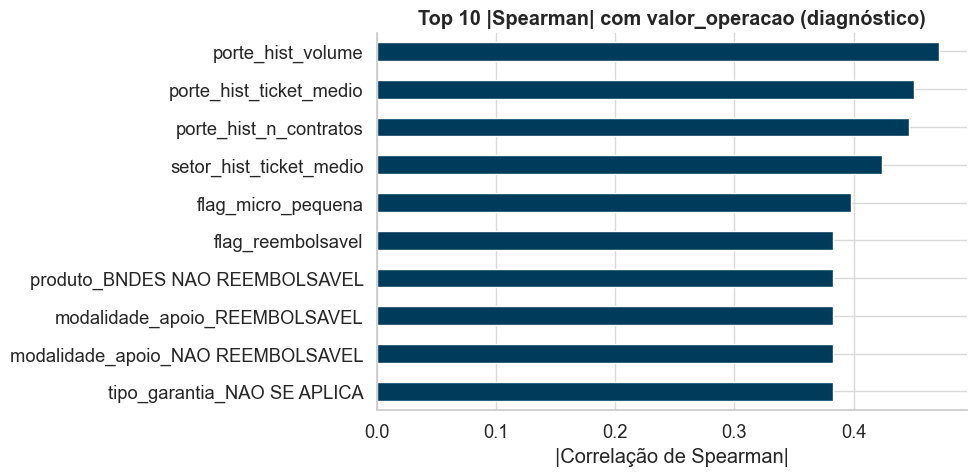

In [15]:
# Gráfico de barras — top 10 correlações absolutas com o alvo
fig, ax = plt.subplots(figsize=(10, 5))
corr.sort_values().plot.barh(ax=ax, color=paleta_cores["azul"])
ax.set_title("Top 10 |Spearman| com valor_operacao (diagnóstico)")
ax.set_xlabel("|Correlação de Spearman|")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 10. Salvamento da camada gold

Salvamos em **parquet** (preserva tipos, é compacto e rápido). A base contém:

- `valor_operacao` (alvo);
- `data_contratacao` (controle para split temporal);
- todas as features numéricas (incluindo one-hot e frequência).

In [16]:
# =============================================================
# 11. SALVAR CAMADA GOLD
# =============================================================
import os
os.makedirs(os.path.dirname(PATH_GOLD), exist_ok=True)

df_feat.to_parquet(PATH_GOLD, index=False)
print(f"Gold salva em: {PATH_GOLD}")
print(f"Shape: {df_feat.shape[0]:,} linhas × {df_feat.shape[1]} colunas")

Gold salva em: ../data/gold/bnds_features.parquet
Shape: 8,294 linhas × 144 colunas


## 11. Checklist da etapa e próximos passos

### Cobertura da ementa
- [x] Construção de atributos a partir de dados reais
- [x] Preparação para correlação, regressão e testes

### O que foi criado
- **Temporais:** `trimestre`, `mes_sin`, `mes_cos`
- **Prazo:** `razao_carencia`, `prazo_total_anos`, `flag_longo_prazo`
- **Geográficas:** `regiao`, `flag_sudeste_sul`
- **Cliente:** `flag_micro_pequena`, `flag_grande`
- **Históricos (time-aware):** `uf_hist_*`, `setor_hist_*`, `porte_hist_*`
- **Redução de cardinalidade:** top-10 + "OUTROS" em 10 colunas categóricas
- **Encoding:** one-hot (≤15 níveis) e frequência (>15 níveis)

### O que foi excluído (e por quê)
- `valor_desembolsado`, `situacao_operacao`
- `cnpj_cliente`, `nome_cliente`, `id_contrato` → **identificadores**
- `descricao_projeto` → **texto bruto** (mantido só `qtd_palavras_descricao`)
- CNAE granular → **redundância**